# Joint multi-sample deconvolution: CRC 480-gene panel

**Author: Su Xu**

Fit tissue sections together while allowing structured expression variation. The CRC example has **102,544 spots in 12 sections from five patients**, $K=10$, and **480 genes retained from a 500-gene candidate panel**. Twenty genes were removed by the comparison's minimum-count filter; they were not replaced. This is the complete matched-panel fit described in the manuscript.

For each patient $d$ and condition group $r$, effective profiles decompose as $B^{(r)}=B_0+\Delta_d+\delta_r$. Patient deviations average to zero across patients; condition deviations average to zero within each patient. Quadratic penalties on both deviation levels are fitted jointly with $P$, and graph edges remain inside physical sections. The unit simplex constraint applies to each effective profile. The shared profile averages patients equally rather than weighting by spot count.

**This tutorial loads the archived full fit. The 12-section model was not retrained for this tutorial release.** The full fitting call is provided for users who choose to rerun it. The archived 480-gene fit converged after 17,525 iterations; the cap was 40,000.

## 1. Set up

Install spDecon using the repository installation instructions, then run this notebook from the cloned repository. The first data-loading cell downloads the versioned data bundle if needed. Saved fits make all plots available on a CPU. Full reference-free training uses the pinned CUDA environment. The saved results are complete fits, not shortened runs. `RUN_FIT=True` executes the full fitting code below; deterministic kernels and a fixed seed support repeatable new fits. Small differences from historical GPU runs may remain.

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from tutorials.common import dataset, correlation, align, spatial, pies, legend, save_figure, save_table
from spDecon.reproducibility import set_seed
set_seed(0, deterministic=True)
# The published outputs inspect complete fitted results. Enable full training explicitly.
RUN_FIT = False


## 2. Load all sections and the patient/condition design

The count matrix preserves every fitted spot. Metadata defines section boundaries, subjects and within-subject condition groups. Pathology is included for display and evaluation only.

In [2]:
path,data=dataset("crc")
metadata=pd.read_csv(path/"metadata.csv.gz",index_col=0)
metadata=metadata.loc[data["spots"]]
print("Counts:",data["Y"].shape)
display(metadata[["section_id","subject_id","condition"]].drop_duplicates())

Counts: (102544, 480)


,section_id,subject_id,condition
spot,,,
M-ST-06~AACAATCCGAGTGGAC-1,M-ST-06,3,post_regimen_single_timepoint
M-ST-09~AACAATCCGAGTGGAC-1,M-ST-09,4,post_regimen_single_timepoint
M-ST-10~AACAATCCGAGTGGAC-1,M-ST-10,4,post_regimen_single_timepoint
IX_56688~AAACACCAATAACTGC-1,IX_56688,5,baseline_before_shown_regimen
IX_56689~AAACAAGTATCTCCCA-1,IX_56689,5,baseline_before_shown_regimen
IX_56690~AAACAAGTATCTCCCA-1,IX_56690,5,baseline_before_shown_regimen
M-ST-17~AACAATCCGAGTGGAC-1,M-ST-17,5,post_regimen_recurrence
M-ST-19~AACAATCCGAGTGGAC-1,M-ST-19,5,post_regimen_recurrence
M-ST-11~AACAATGTGCTCCGAG-1,M-ST-11,6,post_regimen_single_timepoint


## 3. Optionally refit the full hierarchical model

The supplied initialization is the fresh, unrefined count-only consensus for this exact 480-gene matrix, not a fitted hierarchy or another method's factors. The released solver retains the five-cycle auxiliary profile update. Explicit edges preserve the archived graph. Full optimization is memory intensive; the saved fit is sufficient for all subsequent steps.

In [3]:
from spDecon.multisample import fit_multisample
if RUN_FIT:
    initial=np.load(path/"initialization.npz")
    result=fit_multisample(data["Y"],metadata,10,
        group_by=["subject_id","condition"],subject_column="subject_id",
        edges=data["edges"],eta_subject=10.,eta_condition=20.,spatial_weight=.05,
        initial_proportions=initial["P"],initial_profiles=initial["B"][0],
        random_state=0,device="cuda",max_iter=40000)
    p=result.proportions
    shared=result.extra["shared_profiles"]
    patient_delta=result.extra["delta_subject"]
    condition_delta=result.extra["delta_condition"]
    display(result.diagnostics)
else:
    fitted=np.load(path/"fit.npz")
    p,shared=fitted["P"],fitted["B_shared"]
    patient_delta,condition_delta=fitted["Delta_patient"],fitted["delta_condition"]
    print("Loaded the archived complete 12-section fit; no retraining was performed.")
print("P:",p.shape,"Shared profiles:",shared.shape,
      "Patient deviations:",patient_delta.shape,"Condition deviations:",condition_delta.shape)

Loaded the archived complete 12-section fit; no retraining was performed.
P: (102544, 10) Shared profiles: (10, 480) Patient deviations: (5, 10, 480) Condition deviations: (7, 10, 480)


## 4. Display spatial structure in every section

Dominant-component maps use one common component palette. All 12 sections are shown in the input order; no sections are selected by their score. Within-section geometry is preserved, but the panels do not share a physical distance scale.

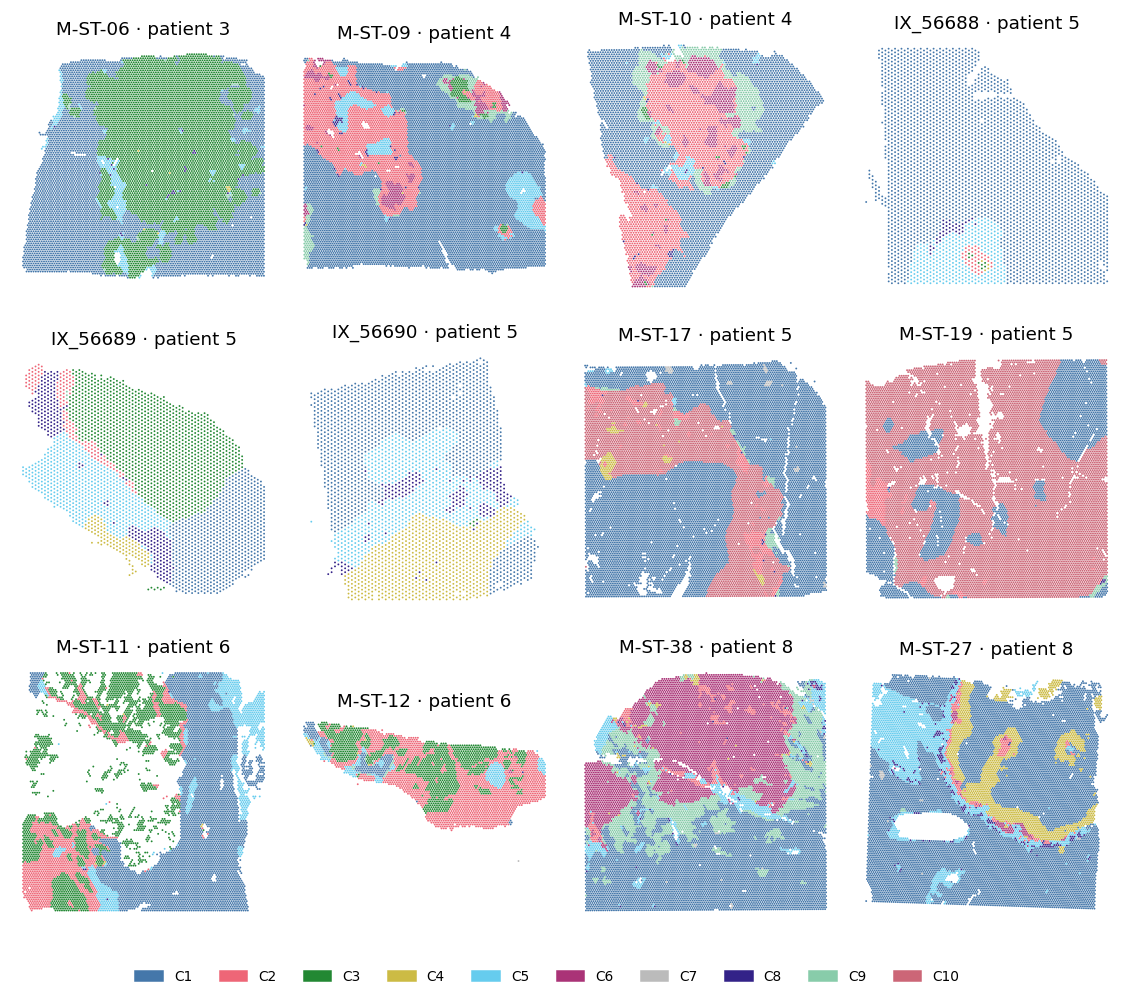

In [4]:
sections=pd.unique(metadata.section_id)
fig,axes=plt.subplots(3,4,figsize=(13,10))
for ax,section in zip(axes.ravel(),sections):
    keep=metadata.section_id.eq(section).to_numpy()
    subject=metadata.loc[keep,"subject_id"].iloc[0]
    spatial(ax,data["coordinates"][keep],p[keep].argmax(axis=1),
            f"{section} · patient {subject}",categorical=True,size=1.5)
legend(fig,[f"C{k+1}" for k in range(10)],columns=10,y=.005)
fig.subplots_adjust(bottom=.07,hspace=.18,wspace=.06)
save_figure(fig,"crc_480_sections")

## 5. Inspect shared markers and the fitted decomposition

The simple marker ranking below divides each shared-profile value by its across-component mean. It summarizes fitted expression patterns and is not a differential-expression test. Patient and condition deviations describe model profiles, not causal treatment effects.

In [5]:
enrichment=shared/np.maximum(shared.mean(axis=0),1e-12)
rows=[]
for k in range(10):
    genes=data["genes"][np.argsort(enrichment[k])[-5:][::-1]]
    rows.append({"component":f"C{k+1}","top_profile_markers":", ".join(genes),
                 "mean_weight":p[:,k].mean()})
display(save_table(pd.DataFrame(rows),"crc_component_summary"))
print("Maximum patient-centering residual:",np.abs(patient_delta.mean(axis=0)).max())
display(pd.read_csv(path/"pathology_partition_metrics.csv"))

,component,top_profile_markers,mean_weight
0,C1,"ALB, HRG, HAL, ITIH2, SLC10A1",0.354468
1,C2,"COL1A2, COL3A1, COL1A1, CTHRC1, VCAN",0.100516
2,C3,"CKB, TSPAN8, MAL2, GPR160, POF1B",0.096236
3,C4,"MMP9, SPP1, GPNMB, MMP12, CHI3L1",0.042018
4,C5,"ADAMTS1, FBLN1, HBA2, SPARCL1, C11orf96",0.081343
5,C6,"FABP1, SPINK1, PLCB4, SLC26A2, SLPI",0.067786
6,C7,"CYP1A2, BHMT, ADH4, RDH16, ADH1A",0.089216
7,C8,"IGKC, IGHA1, IGHG1, IGLC1, IGHM",0.024987
8,C9,"CRP, CREB3L3, HAMP, LBP, FGL1",0.063136
9,C10,"NOTUM, NKD1, SLC2A1, ID1, IER3",0.080294


Maximum patient-centering residual: 4.4408920985006264e-17


,sample,n_annotated,ARI,NMI
0,all,100801,0.448688,0.438661
1,M-ST-06,10265,0.781162,0.650332
2,M-ST-09,11286,0.758429,0.606221
3,M-ST-10,6621,0.589859,0.534549
4,IX_56688,3570,0.311358,0.306289
5,IX_56689,3190,0.413092,0.425107
6,IX_56690,3181,0.422389,0.413425
7,M-ST-17,13226,0.230902,0.335206
8,M-ST-19,13075,0.079232,0.183032
9,M-ST-11,8273,0.720723,0.618556
